# Análisis de Emisiones Globales de CO2 y Modelo de Regresión Lineal

## 1.Carga y Exploración Inicial de Datos

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Configuración visual
sns.set_theme(style="whitegrid")

# 1. CARGA DE DATOS 
df = pd.read_csv('annual-co2-emissions-per-country.csv')

# Revision de primeras filas y estructura
print("Dimensiones originales:", df.shape)
display(df.head())
print("\nValores nulos por columna:\n", df.isnull().sum())

Dimensiones originales: (30219, 4)


,Entity,Code,Year,Annual CO₂ emissions
0,Afghanistan,AFG,1949,14656.0
1,Afghanistan,AFG,1950,80608.0
2,Afghanistan,AFG,1951,87936.0
3,Afghanistan,AFG,1952,87936.0
4,Afghanistan,AFG,1953,98928.0



Valores nulos por columna:
 Entity                     0
Code                    3330
Year                       0
Annual CO₂ emissions       0
dtype: int64


## 2. Limpieza y Transformación de datos

In [2]:
# 2. LIMPIEZA DE DATOS
# Ver el nombre exacto de la columna de emisiones
col_emisiones = df.columns[-1]

# Renombrado de columnas
df_limpio = df.rename(columns={
    'Entity': 'Pais',
    'Code': 'Codigo',
    'Year': 'Anio',
    col_emisiones: 'Emisiones_CO2'
})

# Filtrado de solo países reales
df_paises = df_limpio[df_limpio['Codigo'].notna() & (df_limpio['Codigo'].str.len() == 3)].copy()

# Filtraado desde 1950 en adelante
df_paises = df_paises[df_paises['Anio'] >= 1950]

print("Dimensiones tras limpieza:", df_paises.shape)
display(df_paises.describe())

Dimensiones tras limpieza: (15825, 4)


,Anio,Emisiones_CO2
count,15825.000000,1.582500e+04
mean,1988.728657,1.019375e+08
std,21.730568,5.329087e+08
min,1950.000000,0.000000e+00
25%,1970.000000,4.983040e+05
50%,1989.000000,4.460313e+06
75%,2008.000000,3.595404e+07
max,2025.000000,1.241749e+10


**¿Por qué limpiamos los datos de esta manera?**

1. **Nos quedamos solo con países:** El archivo original mezcla países con regiones enteras (como *World*, *Asia* o grupos por nivel de ingresos). Si los dejábamos todos juntos, íbamos a sumar las mismas emisiones varias veces. Al filtrar únicamente los registros que tienen un código de país de 3 letras (como `COL` o `USA`), nos aseguramos de comparar países reales en igualdad de condiciones.
2. **Analizamos desde 1950 hasta la actualidad:** Aunque la base tiene registros muy antiguos desde 1750, muchos países en desarrollo no tenían mediciones constantes antes de mitad del siglo XX. Al recortar los datos desde 1950 en adelante, logramos una base completa, ordenada y sin datos vacíos.

## 3. Análisis Visual

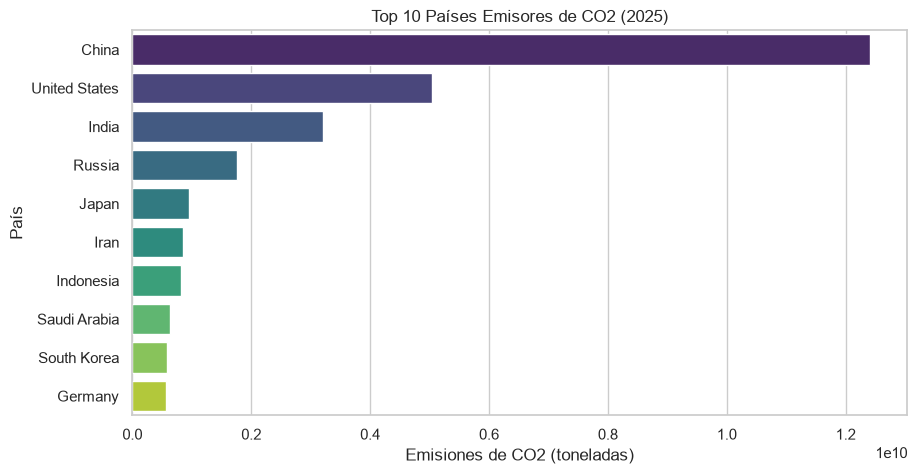

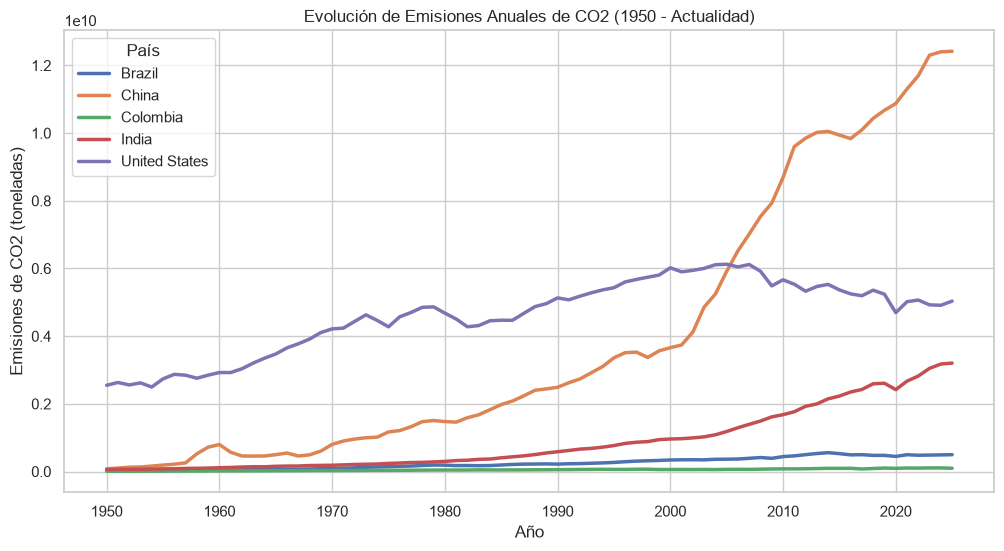

In [3]:
# 3. VISUALIZACIÓN DE DATOS
# Top 10 países con mayores emisiones en el último año registrado
ultimo_anio = df_paises['Anio'].max()
top10 = df_paises[df_paises['Anio'] == ultimo_anio].nlargest(10, 'Emisiones_CO2')

plt.figure(figsize=(10, 5))
sns.barplot(data=top10, x='Emisiones_CO2', y='Pais', hue='Pais', palette='viridis', legend=False)
plt.title(f'Top 10 Países Emisores de CO2 ({ultimo_anio})')
plt.xlabel('Emisiones de CO2 (toneladas)')
plt.ylabel('País')
plt.show()

# Evolución histórica de países clave + Colombia
paises_interes = ['China', 'United States', 'India', 'Colombia', 'Brazil']
df_evolucion = df_paises[df_paises['Pais'].isin(paises_interes)]

plt.figure(figsize=(12, 6))
sns.lineplot(data=df_evolucion, x='Anio', y='Emisiones_CO2', hue='Pais', linewidth=2.5)
plt.title('Evolución de Emisiones Anuales de CO2 (1950 - Actualidad)')
plt.xlabel('Año')
plt.ylabel('Emisiones de CO2 (toneladas)')
plt.legend(title='País')
plt.show()

**¿Qué nos muestran las gráficas?**

* **Los países que más emiten hoy (2025):** La diferencia entre países es enorme. China encabeza la lista por un margen muy amplio (superando los 12 mil millones de toneladas al año), seguida por Estados Unidos e India. Esto confirma lo que explica el artículo de *Our World in Data*: unos pocos países concentran la mayor parte de las emisiones mundiales.
* **Cómo han cambiado desde 1950:** Mientras Estados Unidos mantuvo un crecimiento constante hasta principios de los años 2000 y luego empezó a estabilizarse, China tuvo un salto muy acelerado a partir del año 2000 debido a su rápido crecimiento industrial. Por otro lado, países de nuestra región como Brasil y Colombia tienen niveles mucho más bajos si los comparamos con estas grandes potencias.

## 4. Modelo de Regresión Lineal (Caso Colombia)

Pendiente (incremento anual promedio): 1,249,699.33 toneladas/año
R2 (Coeficiente de determinación): 0.9621
RMSE (Error cuadrático medio raíz): 5,844,088.33


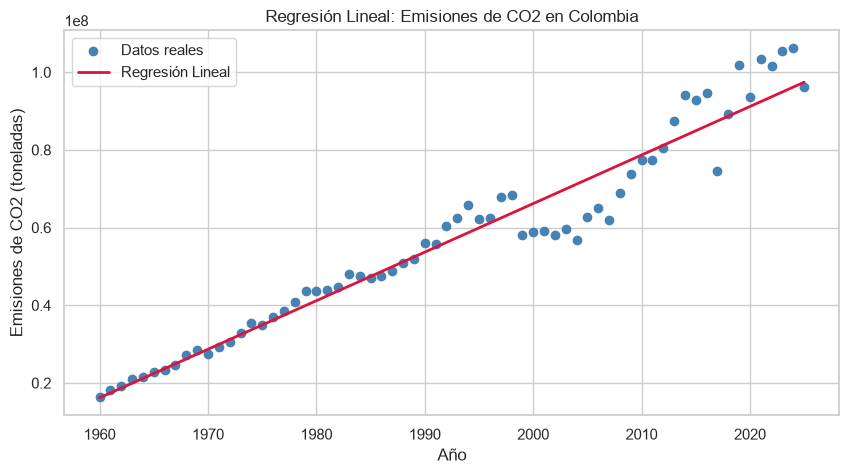

In [4]:
df_modelo = df_paises[(df_paises['Pais'] == 'Colombia') & (df_paises['Anio'] >= 1960)]

X = df_modelo[['Anio']]  # Variable independiente (debe ser 2D)
y = df_modelo['Emisiones_CO2']  # Variable dependiente

# Dividir en entrenamiento (80%) y prueba (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Entrenar modelo
modelo = LinearRegression()
modelo.fit(X_train, y_train)

# Predicciones y métricas
y_pred = modelo.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Pendiente (incremento anual promedio): {modelo.coef_[0]:,.2f} toneladas/año")
print(f"R2 (Coeficiente de determinación): {r2:.4f}")
print(f"RMSE (Error cuadrático medio raíz): {np.sqrt(mse):,.2f}")

# Gráfico de la regresión
plt.figure(figsize=(10, 5))
plt.scatter(X, y, color='steelblue', label='Datos reales')
plt.plot(X, modelo.predict(X), color='crimson', linewidth=2, label='Regresión Lineal')
plt.title('Regresión Lineal: Emisiones de CO2 en Colombia')
plt.xlabel('Año')
plt.ylabel('Emisiones de CO2 (toneladas)')
plt.legend()
plt.show()

## 5. Interpretación de Resultados y Conclusiones

* **¿Qué tan bien funcionó nuestro modelo?** Al analizar el caso de Colombia entre 1960 y 2025, la regresión lineal obtuvo un ajuste del **96,21%** ($R^2 = 0.9621$). Esto significa que una línea recta logra describir muy bien cómo han venido subiendo las emisiones del país con el paso de los años, con un margen de error promedio bajo (alrededor de 5,84 millones de toneladas frente al total anual).
* **¿Cuánto crecen las emisiones cada año?** Según la pendiente de nuestra línea de tendencia, Colombia ha aumentado sus emisiones en un promedio de **1,25 millones de toneladas adicionales cada año** desde 1960.
* **Relación con la lectura de *Our World in Data*:** Como explican Hannah Ritchie y Max Roser en su artículo, el aumento de las emisiones de CO2 suele ir de la mano con el desarrollo económico, el crecimiento de las ciudades y un mayor consumo de energía. Sin embargo, al comparar el caso de Colombia con los países líderes del mundo, queda muy clara la desigualdad global: aunque los países en desarrollo han ido aumentando su huella, siguen representando una parte muy pequeña frente a las grandes potencias industriales, lo que explica por qué el reparto de responsabilidades frente al cambio climático es un tema tan debatido a nivel internacional.